In [1]:
!pip -q install opacus

In [2]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from opacus import PrivacyEngine
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
N_TRAIN = 20_000
EPOCHS = 3
BATCH_SIZE = 256
LR = 1e-3
DELTA = 1e-5
MAX_GRAD_NORM = 1.0
TARGET_EPSILONS = [10.0, 5.0, 1.0]
FIXED_NOISE = 1.1
MAX_ACCEPTABLE_DROP_PP = 5.0


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cuda


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

subset_gen = torch.Generator().manual_seed(SEED)
subset_idx = torch.randperm(len(train_full), generator=subset_gen)[:N_TRAIN].tolist()
train_ds = Subset(train_full, subset_idx)

test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=0)
train_eval_loader = DataLoader(train_ds, batch_size=512, shuffle=False, num_workers=0)

print(f"train subset: {len(train_ds)}   test: {len(test_ds)}")


def make_train_loader():
    return DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED),
    )

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 481kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.11MB/s]

train subset: 20000   test: 10000


In [4]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.gn1 = nn.GroupNorm(8, 32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.gn2 = nn.GroupNorm(8, 64)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.gn1(self.conv1(x))))
        x = self.pool(torch.relu(self.gn2(self.conv2(x))))
        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)


def prepare_run():
    set_seed(SEED)
    model = DigitCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loader = make_train_loader()
    return model, optimizer, loader


criterion = nn.CrossEntropyLoss()
n_params = sum(p.numel() for p in DigitCNN().parameters())
print(f"DigitCNN parameters: {n_params:,}")

DigitCNN parameters: 421,834


In [5]:
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
    return correct / total


def mean_max_softmax(model, loader):
    model.eval()
    total = 0.0
    count = 0
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(DEVICE)
            probs = torch.softmax(model(x), dim=1)
            total += probs.max(dim=1).values.sum().item()
            count += x.size(0)
    return total / count


def fit(model, loader, optimizer, privacy_engine=None):
    eps_history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        seen = 0
        for x, y in loader:
            if y.numel() == 0:
                continue
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * y.size(0)
            seen += y.size(0)
        acc = evaluate(model, test_loader)
        msg = f"  epoch {epoch}/{EPOCHS}  loss={loss_sum / max(seen, 1):.4f}  test_acc={acc * 100:.1f}%"
        if privacy_engine is not None:
            eps = privacy_engine.get_epsilon(delta=DELTA)
            eps_history.append(eps)
            msg += f"  eps={eps:.2f}"
        print(msg)
    return evaluate(model, test_loader), eps_history

### Non private baseline

In [6]:
print("Training baseline (no DP)")
baseline_model, baseline_opt, baseline_loader = prepare_run()
baseline_acc, _ = fit(baseline_model, baseline_loader, baseline_opt)
print(f"Baseline (no DP) : test accuracy {baseline_acc * 100:.1f} %")

Training baseline (no DP)
  epoch 1/3  loss=0.3646  test_acc=96.8%
  epoch 2/3  loss=0.0828  test_acc=97.3%
  epoch 3/3  loss=0.0559  test_acc=97.9%
Baseline (no DP) : test accuracy 97.9 %


## DP models at target ε = 10, 5 and 1

In [7]:
dp_results = []
model_eps1 = None

for target_eps in TARGET_EPSILONS:
    print(f"\nTraining DP model  target eps = {target_eps:g}")
    model, optimizer, loader = prepare_run()
    privacy_engine = PrivacyEngine()
    model, optimizer, loader = privacy_engine.make_private_with_epsilon(
        module=model,
        optimizer=optimizer,
        data_loader=loader,
        epochs=EPOCHS,
        target_epsilon=target_eps,
        target_delta=DELTA,
        max_grad_norm=MAX_GRAD_NORM,
    )
    noise = getattr(optimizer, "noise_multiplier", float("nan"))
    print(f"  calibrated noise_multiplier = {noise:.3f}")
    test_acc, eps_history = fit(model, loader, optimizer, privacy_engine)
    eps_spent = eps_history[-1]
    dp_results.append({
        "target_eps": target_eps,
        "test_acc": test_acc,
        "eps_spent": eps_spent,
        "noise_multiplier": noise,
    })
    if target_eps == 1.0:
        model_eps1 = model

print("\nDP sweep done")
for row in dp_results:
    print(
        f"  target {row['target_eps']:g}  "
        f"test_acc {row['test_acc'] * 100:.1f}%  "
        f"eps_spent {row['eps_spent']:.2f}"
    )


Training DP model  target eps = 10


/usr/local/lib/python3.13/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/opacus/accountants/analysis/rdp.py:332: UserWarning: Optimal order is the largest alpha. Please consider expanding the range of alphas to get a tighter privacy bound.
  warnings.warn(


  calibrated noise_multiplier = 0.491


<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


  epoch 1/3  loss=0.8689  test_acc=89.7%  eps=7.34
  epoch 2/3  loss=0.2666  test_acc=93.8%  eps=8.83
  epoch 3/3  loss=0.2252  test_acc=95.0%  eps=9.99

Training DP model  target eps = 5
  calibrated noise_multiplier = 0.619
  epoch 1/3  loss=0.9737  test_acc=87.9%  eps=3.81
  epoch 2/3  loss=0.2981  test_acc=93.0%  eps=4.47
  epoch 3/3  loss=0.2441  test_acc=94.5%  eps=5.00

Training DP model  target eps = 1
  calibrated noise_multiplier = 1.104
  epoch 1/3  loss=1.2899  test_acc=80.7%  eps=0.65
  epoch 2/3  loss=0.4516  test_acc=89.4%  eps=0.84
  epoch 3/3  loss=0.3161  test_acc=92.4%  eps=1.00

DP sweep done
  target 10  test_acc 95.0%  eps_spent 9.99
  target 5  test_acc 94.5%  eps_spent 5.00
  target 1  test_acc 92.4%  eps_spent 1.00


## Fixed Noise Multiplier

In [8]:
print(f"Training DP model  fixed noise_multiplier = {FIXED_NOISE}")
model_fixed, opt_fixed, loader_fixed = prepare_run()
engine_fixed = PrivacyEngine()
model_fixed, opt_fixed, loader_fixed = engine_fixed.make_private(
    module=model_fixed,
    optimizer=opt_fixed,
    data_loader=loader_fixed,
    noise_multiplier=FIXED_NOISE,
    max_grad_norm=MAX_GRAD_NORM,
)
_, fixed_eps_history = fit(model_fixed, loader_fixed, opt_fixed, engine_fixed)

Training DP model  fixed noise_multiplier = 1.1
  epoch 1/3  loss=1.2880  test_acc=80.7%  eps=0.66
  epoch 2/3  loss=0.4504  test_acc=89.4%  eps=0.85
  epoch 3/3  loss=0.3155  test_acc=92.4%  eps=1.01


## Membership Check

In [9]:
baseline_train_conf = mean_max_softmax(baseline_model, train_eval_loader)
baseline_test_conf = mean_max_softmax(baseline_model, test_loader)
dp_train_conf = mean_max_softmax(model_eps1, train_eval_loader)
dp_test_conf = mean_max_softmax(model_eps1, test_loader)

print(f"Baseline   train {baseline_train_conf:.3f}  test {baseline_test_conf:.3f}")
print(f"DP eps=1   train {dp_train_conf:.3f}  test {dp_test_conf:.3f}")

Baseline   train 0.979  test 0.977
DP eps=1   train 0.930  test 0.936


## Plots

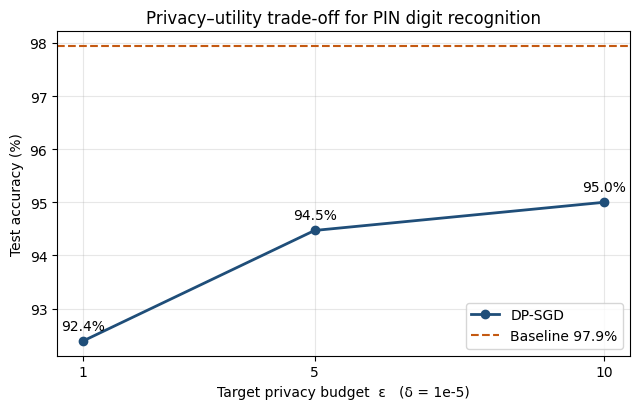

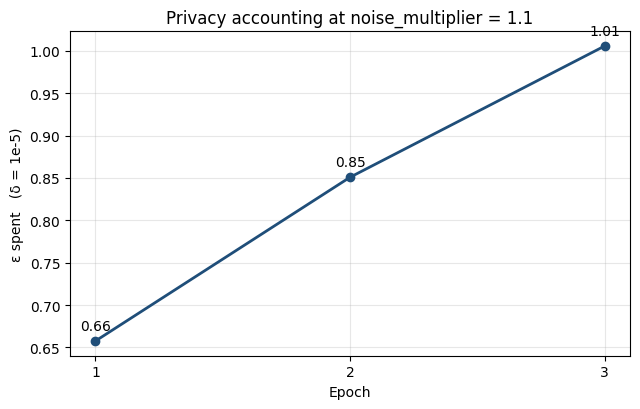

Plot saved : accuracy_vs_epsilon.png
Plot saved : epsilon_vs_epoch.png


In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
xs = [row["target_eps"] for row in dp_results]
ys = [row["test_acc"] * 100 for row in dp_results]
ax.plot(xs, ys, marker="o", color="#1f4e79", linewidth=2, label="DP-SGD")
for x, y in zip(xs, ys):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.axhline(
    baseline_acc * 100,
    color="#c45911",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline {baseline_acc * 100:.1f}%",
)
ax.set_xlabel("Target privacy budget  ε   (δ = 1e-5)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Privacy–utility trade-off for PIN digit recognition")
ax.set_xticks(xs)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.2))
epoch_idx = list(range(1, EPOCHS + 1))
ax.plot(epoch_idx, fixed_eps_history, marker="o", color="#1f4e79", linewidth=2)
for e, eps in zip(epoch_idx, fixed_eps_history):
    ax.annotate(f"{eps:.2f}", (e, eps), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xlabel("Epoch")
ax.set_ylabel("ε spent   (δ = 1e-5)")
ax.set_title(f"Privacy accounting at noise_multiplier = {FIXED_NOISE}")
ax.set_xticks(epoch_idx)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("epsilon_vs_epoch.png", dpi=150)
plt.show()

print("Plot saved : accuracy_vs_epsilon.png")
print("Plot saved : epsilon_vs_epoch.png")

## Results and recommendations

In [13]:
acc_at_1 = next(row["test_acc"] for row in dp_results if row["target_eps"] == 1.0)
cost_at_1 = (acc_at_1 - baseline_acc) * 100

ranked = sorted(dp_results, key=lambda row: row["target_eps"])
acceptable = [
    row for row in ranked
    if (baseline_acc - row["test_acc"]) * 100 <= MAX_ACCEPTABLE_DROP_PP
]
chosen = acceptable[0] if acceptable else ranked[-1]
chosen_cost = (chosen["test_acc"] - baseline_acc) * 100

print(f"Baseline (no DP) : test accuracy {baseline_acc * 100:.1f} %")
print(f"{'TARGET_EPS':<12}{'DELTA':<10}{'CLIP(C)':<10}{'EPOCHS':<8}{'TEST_ACC':<12}{'EPS_SPENT'}")
print("-" * 61)
for row in dp_results:
    acc_txt = f"{row['test_acc'] * 100:>5.1f} %"
    print(
        f"{row['target_eps']:<12.1f}"
        f"{DELTA:<10.0e}"
        f"{MAX_GRAD_NORM:<10.1f}"
        f"{EPOCHS:<8d}"
        f"{acc_txt:<12}"
        f"{row['eps_spent']:.2f}"
    )
print("-" * 61)
print(f"Accuracy cost of strongest privacy (eps = 1) : {cost_at_1:+.1f} %")
print()

print(f"FIXED noise_multiplier = {FIXED_NOISE}")
print(f"{'EPOCH':<8}{'EPSILON_SPENT'}")
print("-" * 21)
for epoch, eps in enumerate(fixed_eps_history, start=1):
    print(f"{epoch:<8d}{eps:.2f}")
print("-" * 21)
print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print(f"{'MODEL':<14}{'TRAIN':>8}{'TEST':>8}{'GAP':>8}")
print("-" * 38)
print(
    f"{'Baseline':<14}"
    f"{baseline_train_conf:8.3f}"
    f"{baseline_test_conf:8.3f}"
    f"{(baseline_train_conf - baseline_test_conf):8.3f}"
)
print(
    f"{'DP (eps=1)':<14}"
    f"{dp_train_conf:8.3f}"
    f"{dp_test_conf:8.3f}"
    f"{(dp_train_conf - dp_test_conf):8.3f}"
)
print("-" * 38)
print()
if chosen["target_eps"] == 1.0:
    print(
        f"Recommended eps : {chosen['target_eps']:g} "
        f"(only {chosen_cost:+.1f} % accuracy, strongest privacy)"
    )
else:
    print(
        f"Recommended eps : {chosen['target_eps']:g} "
        f"({chosen_cost:+.1f} % accuracy; ε = 1 drops more than "
        f"{MAX_ACCEPTABLE_DROP_PP:.0f} points)"
    )

Baseline (no DP) : test accuracy 97.9 %
TARGET_EPS  DELTA     CLIP(C)   EPOCHS  TEST_ACC    EPS_SPENT
-------------------------------------------------------------
10.0        1e-05     1.0       3        95.0 %     9.99
5.0         1e-05     1.0       3        94.5 %     5.00
1.0         1e-05     1.0       3        92.4 %     1.00
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -5.5 %

FIXED noise_multiplier = 1.1
EPOCH   EPSILON_SPENT
---------------------
1       0.66
2       0.85
3       1.01
---------------------
MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL            TRAIN    TEST     GAP
--------------------------------------
Baseline         0.979   0.977   0.003
DP (eps=1)       0.930   0.936  -0.006
--------------------------------------

Recommended eps : 5 (-3.5 % accuracy; ε = 1 drops more than 5 points)
